# CPM comparing behavior

本脚本比较 `highIAT` 与 `lowIAT` 两组在 Age、Sex、Barratt education、Barratt occupation、CBCL internalizing 和 CBCL externalizing 上是否存在差异。

分析分两步：先做不控制协变量的简单组间比较并可视化；随后控制基本协变量，再做组间比较并可视化。连续变量统一使用 `statsmodels.OLS`，`Sex` 是二分变量，单独使用二分类统计模型。


## 1. Imports 与路径

本脚本按照 nested LOOCV 的完整筛选流程核验 FC 数据，仅将通过该流程的同一批 CPM 被试用于行为学比较；后续统计不使用 FC 特征。连续变量使用 `statsmodels` 的公式接口，模型写法接近 R，例如 `target ~ group + covariates`。


In [1]:
# ============================================================
# 1. Imports 与路径
# ============================================================
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

PROJECT_DIR = Path('/Users/yiling/Documents/Codex/HBN_Cdx')
SCRIPTS_DIR = PROJECT_DIR / 'Scripts'
DATA_ROOT = Path.home() / 'Desktop' / 'YiZhang'

# 保留之前脚本的路径习惯：输入和输出均围绕 DATA_ROOT。
# SCRIPTS_DIR 放入 sys.path，用于复用当前项目 Scripts/biox 中的函数。
for package_root in [DATA_ROOT, SCRIPTS_DIR]:
    package_path = str(package_root)
    if package_path in sys.path:
        sys.path.remove(package_path)
    sys.path.insert(0, package_path)

from biox.fcmat import edgeList
from biox.prep import fcMatrixGp

RESULT_DIR = DATA_ROOT / 'CPM_comparingBehav'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print('DATA_ROOT:', DATA_ROOT)
print('RESULT_DIR:', RESULT_DIR)


DATA_ROOT: /Users/yiling/Desktop/YiZhang
RESULT_DIR: /Users/yiling/Desktop/YiZhang/CPM_comparingBehav


## 2. 参数

`GROUP_CUTOFF` 用 IAT 分数定义 `highIAT` / `lowIAT`。`TARGET_COLS` 是本脚本唯一比较的行为变量。


In [2]:
# ============================================================
# 2. 参数
# ============================================================
SCALE_CSV = DATA_ROOT / '量表数据汇总_with_MeanEnorm.csv'
SCHAEFER_DIR = DATA_ROOT / 'HBN_func_Schaefer200'
HO_DIR = DATA_ROOT / 'HBN_func_HarvardOxfordSubcortical'
HO_RAW_INDEX = np.array([4, 5, 6, 7, 9, 10, 11, 15, 16, 17, 18, 19, 20, 21]) - 1

IAT_COL = 'IAT_PCIAT_Total'
SITE_COL = 'ScannerSite'
MOTION_COL = 'mean_enorm'
CBCL_TOTAL_COL = 'CBCL,CBCL_Total_T'
GROUP_CUTOFF = 30
ENORM_CUTOFF = 0.3
CBCL_CUTOFF = 70
EXPECTED_N_TIMEPOINTS = 740

TARGET_COLS = [
    'Basic_Demos,Age',
    'Basic_Demos,Sex',
    'Barratt,Barratt_Total_Edu',
    'Barratt,Barratt_Total_Occ',
    'CBCL,CBCL_Int_T',
    'CBCL,CBCL_Ext_T',
]

# Sex 是二分变量；它比较的是 highIAT 与 lowIAT 的比例差异，而不是连续均值差异。
BINARY_TARGETS = {'Basic_Demos,Sex'}

TARGET_LABELS = {
    'Basic_Demos,Age': 'Age',
    'Basic_Demos,Sex': 'Sex',
    'Barratt,Barratt_Total_Edu': 'Barratt Edu',
    'Barratt,Barratt_Total_Occ': 'Barratt Occ',
    'CBCL,CBCL_Int_T': 'CBCL Int',
    'CBCL,CBCL_Ext_T': 'CBCL Ext',
}

# 基本协变量用于第二步“协变量校正后的组间差异”。
# 若某个 target 本身也在这里，后续会从该 target 的协变量列表中移除，避免“自己控制自己”。
BASE_COVARIATES = [
    'Basic_Demos,Age',
    'Basic_Demos,Sex',
    'Barratt,Barratt_Total_Edu',
    'Barratt,Barratt_Total_Occ',
    MOTION_COL,
    SITE_COL,
]

print('SCALE_CSV:', SCALE_CSV)
print('Targets:', [TARGET_LABELS[col] for col in TARGET_COLS])
print('Base covariates:', BASE_COVARIATES)


SCALE_CSV: /Users/yiling/Desktop/YiZhang/量表数据汇总_with_MeanEnorm.csv
Targets: ['Age', 'Sex', 'Barratt Edu', 'Barratt Occ', 'CBCL Int', 'CBCL Ext']
Base covariates: ['Basic_Demos,Age', 'Basic_Demos,Sex', 'Barratt,Barratt_Total_Edu', 'Barratt,Barratt_Total_Occ', 'mean_enorm', 'ScannerSite']


## 3. 读取数据与定义分析样本

为保证未校正结果、协变量校正结果和 nested LOOCV 可直接对比，本脚本逐项复用 nested LOOCV 的样本筛选：两个 atlas 的两个 run 均存在、拼接后均为 740 个时间点、FC edge 全部为有限值、IAT 与协变量完整、`CBCL total <70` 且 `mean_enorm <0.3`。`group_code=1` 表示 `highIAT`，`group_code=0` 表示 `lowIAT`。


In [3]:
# ============================================================
# 3. 读取数据与定义分析样本
# ============================================================
df_raw = pd.read_csv(SCALE_CSV)
df_raw['ID'] = df_raw['ID'].astype(str)
df_raw['func1'] = 'sub-' + df_raw['ID'] + '_func1.npy'
df_raw['func2'] = 'sub-' + df_raw['ID'] + '_func2.npy'

required_cols = list(dict.fromkeys([IAT_COL, CBCL_TOTAL_COL] + TARGET_COLS + BASE_COVARIATES))
missing_cols = [col for col in required_cols if col not in df_raw.columns]
if missing_cols:
    raise KeyError(f'Columns not found: {missing_cols}')

# 与 nested LOOCV 一致：两个 atlas 中必须同时存在两个 run。
files_present_in_both_atlases = set(os.listdir(SCHAEFER_DIR)) & set(os.listdir(HO_DIR))
df_fc = df_raw[
    df_raw['func1'].isin(files_present_in_both_atlases)
    & df_raw['func2'].isin(files_present_in_both_atlases)
].reset_index(drop=True)

# 与 nested LOOCV 使用相同的时间点检查、ROI 组合和 FC 计算。
fc_list = []
timepoint_ok_row_idx = []
for i in range(df_fc.shape[0]):
    f1 = df_fc.loc[i, 'func1']
    f2 = df_fc.loc[i, 'func2']

    sch1 = np.load(SCHAEFER_DIR / f1)
    sch2 = np.load(SCHAEFER_DIR / f2)
    ho1 = np.load(HO_DIR / f1)
    ho2 = np.load(HO_DIR / f2)

    if (sch1.shape[1] + sch2.shape[1] != EXPECTED_N_TIMEPOINTS) or (ho1.shape[1] + ho2.shape[1] != EXPECTED_N_TIMEPOINTS):
        continue

    ts_sch = np.concatenate([sch1, sch2], axis=1)
    ts_ho = np.concatenate([ho1, ho2], axis=1)[HO_RAW_INDEX, :]
    ts = np.concatenate([ts_sch, ts_ho], axis=0)
    fc_z = fcMatrixGp(ts[np.newaxis, :, :], fisherZ=True)[0]
    fc_list.append(edgeList(fc_z, k=1))
    timepoint_ok_row_idx.append(i)

df_fc = df_fc.iloc[timepoint_ok_row_idx].reset_index(drop=True)
FC_all = np.asarray(fc_list, dtype=np.float32)

# SITE_COL 是分类变量；其余分析列转换为数值。
df = df_fc.copy()
for col in required_cols:
    if col != SITE_COL:
        df[col] = pd.to_numeric(df[col], errors='coerce')

analysis_mask = (
    df[required_cols].notna().all(axis=1).to_numpy()
    & np.isfinite(df[IAT_COL].to_numpy(dtype=float))
    & np.isfinite(df[MOTION_COL].to_numpy(dtype=float))
    & (df[MOTION_COL].to_numpy(dtype=float) < ENORM_CUTOFF)
    & (df[CBCL_TOTAL_COL].to_numpy(dtype=float) < CBCL_CUTOFF)
    & np.isfinite(FC_all).all(axis=1)
)

df_analysis = df.loc[analysis_mask].reset_index(drop=True)
y_iat = df_analysis[IAT_COL].to_numpy(dtype=float)
group_code = (y_iat > GROUP_CUTOFF).astype(int)
group_name = np.where(group_code == 1, 'highIAT', 'lowIAT')

sample_summary = {
    'n_raw_subjects': int(df_raw.shape[0]),
    'n_analysis_subjects': int(df_analysis.shape[0]),
    'n_lowIAT': int(np.sum(group_code == 0)),
    'n_highIAT': int(np.sum(group_code == 1)),
    'IAT_cutoff': float(GROUP_CUTOFF),
    'motion_filter': f'{MOTION_COL} < {ENORM_CUTOFF}',
    'CBCL_filter': f'{CBCL_TOTAL_COL} < {CBCL_CUTOFF}',
    'expected_timepoints': int(EXPECTED_N_TIMEPOINTS),
}

print(json.dumps(sample_summary, ensure_ascii=False, indent=2))
display(pd.Series(group_name, name='IAT_group').value_counts().to_frame('N'))


/Users/yiling/Documents/Codex/HBN_Cdx/Scripts/biox/prep.py:623: RuntimeWarning: divide by zero encountered in arctanh
  fcMatrixGp = np.arctanh(fcMatrixGp)


{
  "n_raw_subjects": 1387,
  "n_analysis_subjects": 1114,
  "n_lowIAT": 653,
  "n_highIAT": 461,
  "IAT_cutoff": 30.0,
  "motion_filter": "mean_enorm < 0.3",
  "CBCL_filter": "CBCL,CBCL_Total_T < 70",
  "expected_timepoints": 740
}


,N
IAT_group,
lowIAT,653
highIAT,461


## 4. 未校正的组间差异

这里直接比较 `highIAT` 与 `lowIAT` 的原始组间差异。连续变量使用 `target ~ group` 的 OLS；`group` 系数就是 `highIAT - lowIAT` 的均值差。`Sex` 使用 2×2 Fisher exact test 比较 `Sex=1` 的比例差。


In [4]:
# ============================================================
# 4. 未校正的组间差异
# ============================================================
result_rows = []
value_rows = []

for target in TARGET_COLS:
    y_target = df_analysis[target].to_numpy(dtype=float)
    high_values = y_target[group_code == 1]
    low_values = y_target[group_code == 0]

    if target in BINARY_TARGETS:
        # Sex 是二分变量。这里先确认它确实只包含两个取值；随后把“取值较大者”
        # 作为 1 类，比较 highIAT 与 lowIAT 中 1 类的比例是否不同。
        # 若你的 Sex 编码为 0/1，这一步就是比较 Sex=1 的比例。
        unique_values = np.sort(np.unique(y_target))
        if unique_values.size != 2:
            raise ValueError(f'{target} must contain exactly two values, got {unique_values}.')
        positive_value = float(unique_values[-1])
        y_binary = (y_target == positive_value).astype(int)
        high_binary = y_binary[group_code == 1]
        low_binary = y_binary[group_code == 0]

        # 2×2 列联表：行是 IAT 分组，列是 Sex=0/1。
        # Fisher exact test 对 2×2 表稳健；同时给出 chi-square p 值便于审阅。
        table = np.array([
            [np.sum(low_binary == 0), np.sum(low_binary == 1)],
            [np.sum(high_binary == 0), np.sum(high_binary == 1)],
        ])
        odds_ratio, fisher_p = stats.fisher_exact(table)
        chi2, chi2_p, _, _ = stats.chi2_contingency(table)

        high_mean = float(high_binary.mean())
        low_mean = float(low_binary.mean())
        difference = high_mean - low_mean
        high_se = float(np.sqrt(high_mean * (1 - high_mean) / high_binary.size))
        low_se = float(np.sqrt(low_mean * (1 - low_mean) / low_binary.size))
        test_model = 'fisher_exact_2x2'
        statistic_name = 'odds_ratio'
        statistic = float(odds_ratio)
        p_two_sided = float(fisher_p)
        extra_p_chi2 = float(chi2_p)
        cohen_d = np.nan
        partial_eta2 = np.nan

        values_for_plot = y_binary.astype(float)

    else:
        # 连续变量统一使用 statsmodels 的公式接口，写法接近 R。
        # 未校正模型为：
        #   Q("target") ~ group_highIAT
        #
        # Q("...") 用来保护含逗号的原始列名，例如 "CBCL,CBCL_Ext_T"；
        # group_highIAT=1 表示 highIAT、=0 表示 lowIAT，因此该系数可直接
        # 解释为 highIAT - lowIAT 的原始均值差。
        model_df = df_analysis.copy()
        model_df['group_highIAT'] = group_code.astype(float)
        formula = f'Q("{target}") ~ group_highIAT'
        ols_fit = smf.ols(formula=formula, data=model_df).fit()

        high_mean = float(high_values.mean())
        low_mean = float(low_values.mean())
        difference = float(ols_fit.params['group_highIAT'])
        statistic = float(ols_fit.tvalues['group_highIAT'])
        p_two_sided = float(ols_fit.pvalues['group_highIAT'])
        df_error = float(ols_fit.df_resid)

        # partial eta squared 是 OLS 中常用的效应量：
        #   partial_eta2 = t^2 / (t^2 + df_error)
        # 它表示 group 这一项相对于残差方差的解释强度。
        partial_eta2 = float(statistic**2 / (statistic**2 + df_error))

        # Cohen's d 作为两组均值差的直观效应量：均值差 / pooled SD。
        # 方向同样是 highIAT - lowIAT。
        n_high = high_values.size
        n_low = low_values.size
        pooled_var = (
            (n_high - 1) * np.var(high_values, ddof=1)
            + (n_low - 1) * np.var(low_values, ddof=1)
        ) / (n_high + n_low - 2)
        pooled_sd = np.sqrt(pooled_var)
        cohen_d = float(difference / pooled_sd) if pooled_sd > 0 else np.nan

        test_model = 'ols'
        statistic_name = 't'
        odds_ratio = np.nan
        extra_p_chi2 = np.nan
        values_for_plot = y_target
        high_se = np.nan
        low_se = np.nan

    result_rows.append({
        'target': target,
        'target_label': TARGET_LABELS[target],
        'variable_type': 'binary' if target in BINARY_TARGETS else 'continuous',
        'test_model': test_model,
        'n_subjects': int(df_analysis.shape[0]),
        'n_highIAT': int(np.sum(group_code == 1)),
        'n_lowIAT': int(np.sum(group_code == 0)),
        'mean_highIAT': high_mean,
        'mean_lowIAT': low_mean,
        'se_highIAT': high_se,
        'se_lowIAT': low_se,
        'difference_high_minus_low': difference,
        'cohen_d': cohen_d,
        'partial_eta2': partial_eta2,
        'odds_ratio': odds_ratio,
        'statistic_name': statistic_name,
        'statistic': statistic,
        'p_two_sided': p_two_sided,
        'chi2_p_two_sided': extra_p_chi2,
    })

    for subgroup, values in [('highIAT', values_for_plot[group_code == 1]), ('lowIAT', values_for_plot[group_code == 0])]:
        for value in values:
            value_rows.append({
                'target': target,
                'target_label': TARGET_LABELS[target],
                'subgroup': subgroup,
                'raw_value': float(value),
            })

results_df = pd.DataFrame(result_rows)
values_df = pd.DataFrame(value_rows)

# 6 个目标变量同时检验，报告 Benjamini-Hochberg FDR q 值。
p = results_df['p_two_sided'].to_numpy(dtype=float)
order = np.argsort(p)
ranked_p = p[order]
q_ranked = ranked_p * len(ranked_p) / np.arange(1, len(ranked_p) + 1)
q_ranked = np.minimum.accumulate(q_ranked[::-1])[::-1]
q_ranked = np.minimum(q_ranked, 1.0)
q = np.empty_like(q_ranked)
q[order] = q_ranked
results_df['q_fdr'] = q

results_path = RESULT_DIR / 'CPM_comparingBehav_raw_group_differences.csv'
values_path = RESULT_DIR / 'CPM_comparingBehav_raw_values.csv'
results_df.to_csv(results_path, index=False)
values_df.to_csv(values_path, index=False)

print('Saved:', results_path)
print('Saved:', values_path)
print('Unadjusted effect sizes:')
display(results_df[['target_label', 'variable_type', 'difference_high_minus_low', 'cohen_d', 'partial_eta2', 'odds_ratio', 'p_two_sided', 'q_fdr']])
display(results_df.sort_values('p_two_sided'))


Saved: /Users/yiling/Desktop/YiZhang/CPM_comparingBehav/CPM_comparingBehav_raw_group_differences.csv
Saved: /Users/yiling/Desktop/YiZhang/CPM_comparingBehav/CPM_comparingBehav_raw_values.csv
Unadjusted effect sizes:


,target_label,variable_type,difference_high_minus_low,cohen_d,partial_eta2,odds_ratio,p_two_sided,q_fdr
0,Age,continuous,2.326782,0.762443,0.123780,NaN,8.366464e-34,5.019879e-33
1,Sex,binary,-0.139526,NaN,NaN,0.555769,3.367656e-06,5.051484e-06
2,Barratt Edu,continuous,-0.043450,-0.014497,0.000051,NaN,8.116860e-01,8.116860e-01
3,Barratt Occ,continuous,0.656124,0.056553,0.000777,NaN,3.527560e-01,4.233072e-01
4,CBCL Int,continuous,3.476958,0.347179,0.028457,NaN,1.472619e-08,2.945238e-08
5,CBCL Ext,continuous,3.684430,0.373900,0.032857,NaN,1.102951e-09,3.308852e-09


,target,target_label,variable_type,test_model,n_subjects,n_highIAT,n_lowIAT,mean_highIAT,mean_lowIAT,se_highIAT,se_lowIAT,difference_high_minus_low,cohen_d,partial_eta2,odds_ratio,statistic_name,statistic,p_two_sided,chi2_p_two_sided,q_fdr
0,"Basic_Demos,Age",Age,continuous,ols,1114,461,653,12.962971,10.636190,NaN,NaN,2.326782,0.762443,0.123780,NaN,t,12.533488,8.366464e-34,NaN,5.019879e-33
5,"CBCL,CBCL_Ext_T",CBCL Ext,continuous,ols,1114,461,653,52.806941,49.122511,NaN,NaN,3.684430,0.373900,0.032857,NaN,t,6.146381,1.102951e-09,NaN,3.308852e-09
4,"CBCL,CBCL_Int_T",CBCL Int,continuous,ols,1114,461,653,56.559653,53.082695,NaN,NaN,3.476958,0.347179,0.028457,NaN,t,5.707135,1.472619e-08,NaN,2.945238e-08
1,"Basic_Demos,Sex",Sex,binary,fisher_exact_2x2,1114,461,653,0.327549,0.467075,0.021858,0.019524,-0.139526,NaN,NaN,0.555769,odds_ratio,0.555769,3.367656e-06,0.000004,5.051484e-06
3,"Barratt,Barratt_Total_Occ",Barratt Occ,continuous,ols,1114,461,653,33.611714,32.955590,NaN,NaN,0.656124,0.056553,0.000777,NaN,t,0.929646,3.527560e-01,NaN,4.233072e-01
2,"Barratt,Barratt_Total_Edu",Barratt Edu,continuous,ols,1114,461,653,17.977223,18.020674,NaN,NaN,-0.043450,-0.014497,0.000051,NaN,t,-0.238308,8.116860e-01,NaN,8.116860e-01


## 5. 未校正结果可视化

第一张图显示所有变量的未校正 `highIAT - lowIAT` 差异。第二张图只显示连续变量的原始取值分布。`Sex` 作为二分变量单独画成比例图：柱高表示两组中 `Sex=1` 的比例。


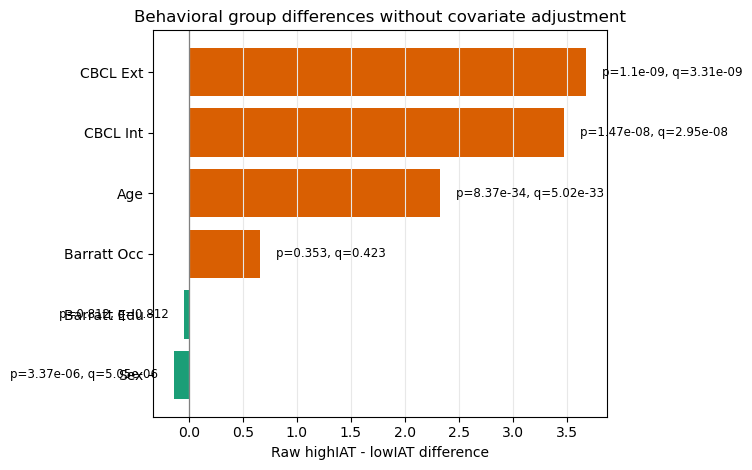

Saved: /Users/yiling/Desktop/YiZhang/CPM_comparingBehav/CPM_comparingBehav_raw_group_differences.png


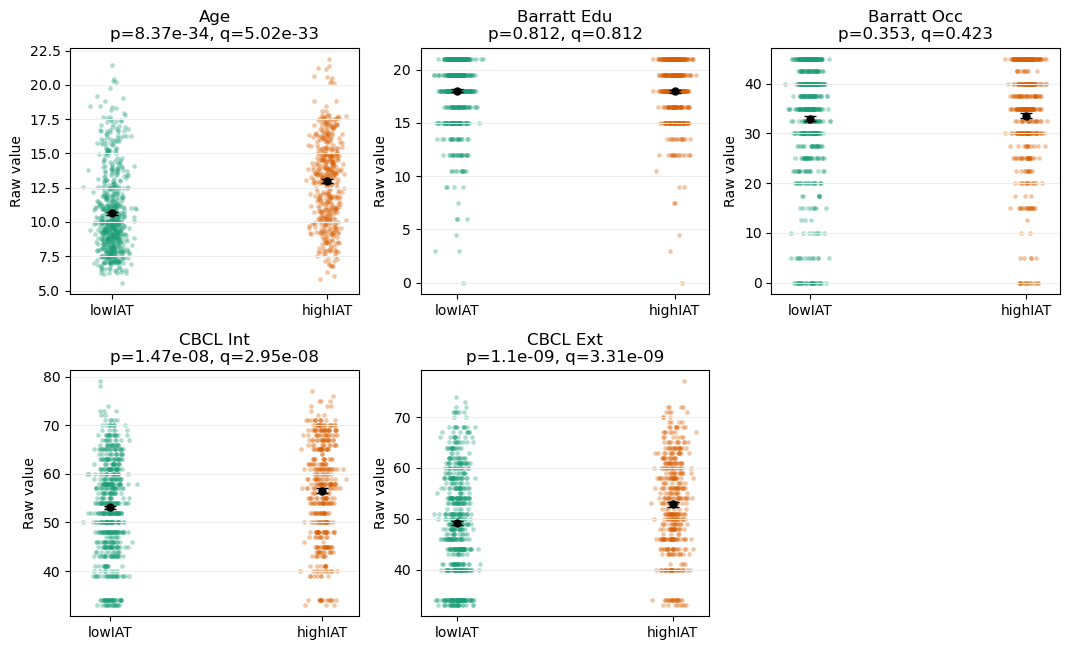

Saved: /Users/yiling/Desktop/YiZhang/CPM_comparingBehav/CPM_comparingBehav_raw_continuous_values.png


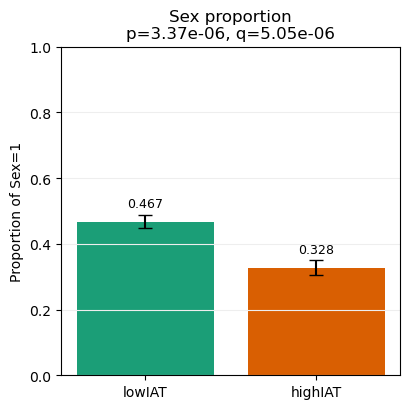

Saved: /Users/yiling/Desktop/YiZhang/CPM_comparingBehav/CPM_comparingBehav_raw_sex_proportion.png


In [5]:
# ============================================================
# 5. 未校正结果可视化
# ============================================================
plot_df = results_df.copy().sort_values('difference_high_minus_low')

# 5.1 未校正的 high-low 差异。
fig, ax = plt.subplots(figsize=(7.6, 4.8))
y_pos = np.arange(plot_df.shape[0])
bar_colors = ['#d95f02' if v >= 0 else '#1b9e77' for v in plot_df['difference_high_minus_low']]
ax.barh(y_pos, plot_df['difference_high_minus_low'], color=bar_colors)
ax.axvline(0, color='#808080', linewidth=0.9)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['target_label'])
ax.set_xlabel('Raw highIAT - lowIAT difference')
ax.set_title('Behavioral group differences without covariate adjustment')
ax.grid(True, axis='x', color='#e8e8e8', linewidth=0.8)

x_span = max(plot_df['difference_high_minus_low'].abs().max(), 1e-6)
x_pad = 0.04 * x_span
for row_idx, row in enumerate(plot_df.itertuples(index=False)):
    x = row.difference_high_minus_low
    x_text = x + x_pad if x >= 0 else x - x_pad
    ha = 'left' if x >= 0 else 'right'
    ax.text(
        x_text,
        row_idx,
        f'p={row.p_two_sided:.3g}, q={row.q_fdr:.3g}',
        va='center',
        ha=ha,
        fontsize=8.5,
    )

fig.tight_layout()
bar_fig_path = RESULT_DIR / 'CPM_comparingBehav_raw_group_differences.png'
fig.savefig(bar_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', bar_fig_path)

# 5.2 连续变量的原始取值分布。
continuous_targets = [target for target in TARGET_COLS if target not in BINARY_TARGETS]
fig, axes = plt.subplots(2, 3, figsize=(10.8, 6.6))
axes = axes.ravel()

rng = np.random.default_rng(2026)
group_order = ['lowIAT', 'highIAT']
group_colors = {'lowIAT': '#1b9e77', 'highIAT': '#d95f02'}

for ax, target in zip(axes, continuous_targets):
    sub_df = values_df[values_df['target'] == target]
    for x_idx, subgroup in enumerate(group_order):
        values = sub_df.loc[sub_df['subgroup'] == subgroup, 'raw_value'].to_numpy(dtype=float)
        jitter = rng.normal(0, 0.035, size=values.size)
        ax.scatter(
            np.full(values.size, x_idx) + jitter,
            values,
            s=11,
            alpha=0.35,
            color=group_colors[subgroup],
            linewidths=0,
        )
        mean = values.mean()
        sem = values.std(ddof=1) / np.sqrt(values.size)
        ax.errorbar(x_idx, mean, yerr=sem, fmt='o', color='black', capsize=4, markersize=5, linewidth=1.2)

    p_value = results_df.loc[results_df['target'] == target, 'p_two_sided'].iloc[0]
    q_value = results_df.loc[results_df['target'] == target, 'q_fdr'].iloc[0]
    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels(group_order)
    ax.set_title(f'{TARGET_LABELS[target]}\np={p_value:.3g}, q={q_value:.3g}')
    ax.set_ylabel('Raw value')
    ax.grid(True, axis='y', color='#eeeeee', linewidth=0.8)

for ax in axes[len(continuous_targets):]:
    ax.axis('off')

fig.tight_layout()
value_fig_path = RESULT_DIR / 'CPM_comparingBehav_raw_continuous_values.png'
fig.savefig(value_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', value_fig_path)

# 5.3 Sex 单独画比例图。
sex_row = results_df.loc[results_df['target'].isin(BINARY_TARGETS)].iloc[0]
sex_means = [sex_row['mean_lowIAT'], sex_row['mean_highIAT']]
sex_ses = [sex_row['se_lowIAT'], sex_row['se_highIAT']]

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.bar(group_order, sex_means, yerr=sex_ses, capsize=5, color=[group_colors[g] for g in group_order])
ax.set_ylim(0, 1)
ax.set_ylabel('Proportion of Sex=1')
ax.set_title(f'Sex proportion\np={sex_row.p_two_sided:.3g}, q={sex_row.q_fdr:.3g}')
ax.grid(True, axis='y', color='#eeeeee', linewidth=0.8)

for x_idx, value in enumerate(sex_means):
    ax.text(x_idx, value + 0.035, f'{value:.3f}', ha='center', va='bottom', fontsize=9)

fig.tight_layout()
sex_fig_path = RESULT_DIR / 'CPM_comparingBehav_raw_sex_proportion.png'
fig.savefig(sex_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', sex_fig_path)


## 6. 协变量校正后的组间差异

这里在同一批被试中进一步控制基本协变量。连续变量使用接近 R 的公式写法：`target ~ group_highIAT + covariates`；`group_highIAT` 系数表示控制协变量后的 `highIAT - lowIAT` 差异。`Sex` 是二分变量，因此使用 logistic GLM 的公式写法。


In [6]:
# ============================================================
# 6. 协变量校正后的组间差异
# ============================================================
adjusted_rows = []
adjusted_value_rows = []

for target in TARGET_COLS:
    # target 本身若属于基本协变量，必须从当前模型的协变量中移除。
    # 例如检验 Age 的组间差异时，不能同时把 Age 当协变量；
    # 检验 Sex 的组间差异时，也不能把 Sex 本身放进模型右侧。
    covariate_cols = [col for col in BASE_COVARIATES if col != target]

    # formula_terms 是 R 风格模型右侧的协变量部分。
    # - 连续/二值协变量写成 Q("列名")，用于保护逗号等特殊字符；
    # - ScannerSite 是分类变量，写成 C(Q("ScannerSite"))，由 statsmodels 自动展开为 dummy coding。
    formula_terms = [
        f'C(Q("{col}"))' if col == SITE_COL else f'Q("{col}")'
        for col in covariate_cols
    ]
    rhs = 'group_highIAT + ' + ' + '.join(formula_terms)
    cov_only_rhs = ' + '.join(formula_terms)

    model_df = df_analysis.copy()
    model_df['group_highIAT'] = group_code.astype(float)

    y_target = df_analysis[target].to_numpy(dtype=float)
    raw_high = y_target[group_code == 1]
    raw_low = y_target[group_code == 0]

    if target in BINARY_TARGETS:
        # Sex 是二分变量，校正后问题是：在控制协变量后，highIAT 与 lowIAT
        # 两组 Sex=1 的概率是否不同。
        #
        # 模型：logit(P(Sex=1)) = intercept + group + covariates。
        # p 值来自 group 系数的 Wald 检验；odds_ratio 是 highIAT 相对 lowIAT 的 odds ratio。
        unique_values = np.sort(np.unique(y_target))
        if unique_values.size != 2:
            raise ValueError(f'{target} must contain exactly two values, got {unique_values}.')
        positive_value = float(unique_values[-1])
        y_binary = (y_target == positive_value).astype(float)

        model_df['sex_binary'] = y_binary
        formula = f'sex_binary ~ {rhs}'
        logit_fit = smf.glm(
            formula=formula,
            data=model_df,
            family=sm.families.Binomial(),
        ).fit()
        logit_coef = float(logit_fit.params['group_highIAT'])
        odds_ratio = float(np.exp(logit_coef))
        p_two_sided = float(logit_fit.pvalues['group_highIAT'])
        statistic = float(logit_fit.tvalues['group_highIAT'])

        # 为了让结果仍然在原始概率尺度上可解释，这里计算 marginal probability difference：
        # 保留每个被试自己的协变量不变，只把所有人的 group 分别设为 0/1，
        # 再比较两种情形下平均预测 P(Sex=1)。
        model_df_low = model_df.copy()
        model_df_high = model_df.copy()
        model_df_low['group_highIAT'] = 0.0
        model_df_high['group_highIAT'] = 1.0
        pred_low = logit_fit.predict(model_df_low).to_numpy(dtype=float)
        pred_high = logit_fit.predict(model_df_high).to_numpy(dtype=float)
        mean_low = float(pred_low.mean())
        mean_high = float(pred_high.mean())
        difference = mean_high - mean_low
        low_se = float(pred_low.std(ddof=1) / np.sqrt(pred_low.size))
        high_se = float(pred_high.std(ddof=1) / np.sqrt(pred_high.size))

        # 可视化中展示 covariate-only logistic model 的 response residual。
        # 它表示“真实 0/1 Sex”减去“仅由协变量预测的 Sex=1 概率”。
        cov_only_formula = f'sex_binary ~ {cov_only_rhs}'
        cov_only_fit = smf.glm(
            formula=cov_only_formula,
            data=model_df,
            family=sm.families.Binomial(),
        ).fit()
        values_for_plot = y_binary - cov_only_fit.predict(model_df)

        variable_type = 'binary'
        test_model = 'logistic_glm'
        statistic_name = 'z'
        logit_coef_out = logit_coef
        partial_eta2 = np.nan
        cohen_d = np.nan
        df_error = np.nan

    else:
        # 连续变量统一使用 statsmodels 的公式接口。
        # 校正后模型为：
        #   Q("target") ~ group_highIAT + covariates
        #
        # 其中 group_highIAT 的系数就是控制这些协变量后的 highIAT - lowIAT 差异。
        formula = f'Q("{target}") ~ {rhs}'
        ols_fit = smf.ols(formula=formula, data=model_df).fit()
        difference = float(ols_fit.params['group_highIAT'])
        statistic = float(ols_fit.tvalues['group_highIAT'])
        p_two_sided = float(ols_fit.pvalues['group_highIAT'])
        df_error = float(ols_fit.df_resid)

        # partial eta squared 来自 group 项的 t 值和残差自由度：
        #   partial_eta2 = t^2 / (t^2 + df_error)
        # 直观上，它表示在已经控制协变量后，group 项还能解释多少相对残差变异。
        partial_eta2 = float(statistic**2 / (statistic**2 + df_error))

        # marginal mean difference：保持每个被试自己的协变量不变，只把 group 设为 0/1，
        # 再比较两种情况下的平均预测值。在线性 OLS 中，这个差异应等于 group 系数。
        model_df_low = model_df.copy()
        model_df_high = model_df.copy()
        model_df_low['group_highIAT'] = 0.0
        model_df_high['group_highIAT'] = 1.0
        mean_low = float(ols_fit.predict(model_df_low).mean())
        mean_high = float(ols_fit.predict(model_df_high).mean())
        low_se = np.nan
        high_se = np.nan

        # 可视化中展示 covariate-only OLS 的 residual，用来直观看控制协变量后
        # highIAT 与 lowIAT 是否仍有系统性偏移。
        cov_only_formula = f'Q("{target}") ~ {cov_only_rhs}'
        cov_only_fit = smf.ols(formula=cov_only_formula, data=model_df).fit()
        values_for_plot = y_target - cov_only_fit.predict(model_df)

        high_resid = values_for_plot[group_code == 1]
        low_resid = values_for_plot[group_code == 0]
        n_high = high_resid.size
        n_low = low_resid.size
        pooled_var = (
            (n_high - 1) * np.var(high_resid, ddof=1)
            + (n_low - 1) * np.var(low_resid, ddof=1)
        ) / (n_high + n_low - 2)
        pooled_sd = np.sqrt(pooled_var)
        cohen_d = float((high_resid.mean() - low_resid.mean()) / pooled_sd) if pooled_sd > 0 else np.nan

        variable_type = 'continuous'
        test_model = 'ols'
        statistic_name = 't'
        logit_coef_out = np.nan
        odds_ratio = np.nan

    adjusted_rows.append({
        'target': target,
        'target_label': TARGET_LABELS[target],
        'variable_type': variable_type,
        'test_model': test_model,
        'n_subjects': int(df_analysis.shape[0]),
        'n_highIAT': int(np.sum(group_code == 1)),
        'n_lowIAT': int(np.sum(group_code == 0)),
        'raw_mean_highIAT': float(raw_high.mean()),
        'raw_mean_lowIAT': float(raw_low.mean()),
        'adjusted_mean_highIAT': mean_high,
        'adjusted_mean_lowIAT': mean_low,
        'adjusted_se_highIAT': high_se,
        'adjusted_se_lowIAT': low_se,
        'adjusted_difference_high_minus_low': difference,
        'cohen_d_adjusted': cohen_d,
        'partial_eta2': partial_eta2,
        'logit_coef': logit_coef_out,
        'odds_ratio': odds_ratio,
        'statistic_name': statistic_name,
        'statistic': statistic,
        'df_error': df_error,
        'p_two_sided': p_two_sided,
        'covariates': '; '.join(covariate_cols),
    })

    for subgroup, values in [('highIAT', values_for_plot[group_code == 1]), ('lowIAT', values_for_plot[group_code == 0])]:
        for value in values:
            adjusted_value_rows.append({
                'target': target,
                'target_label': TARGET_LABELS[target],
                'subgroup': subgroup,
                'covariate_adjusted_value': float(value),
            })

adjusted_results_df = pd.DataFrame(adjusted_rows)
adjusted_values_df = pd.DataFrame(adjusted_value_rows)

p = adjusted_results_df['p_two_sided'].to_numpy(dtype=float)
order = np.argsort(p)
ranked_p = p[order]
q_ranked = ranked_p * len(ranked_p) / np.arange(1, len(ranked_p) + 1)
q_ranked = np.minimum.accumulate(q_ranked[::-1])[::-1]
q_ranked = np.minimum(q_ranked, 1.0)
q = np.empty_like(q_ranked)
q[order] = q_ranked
adjusted_results_df['q_fdr'] = q

adjusted_results_path = RESULT_DIR / 'CPM_comparingBehav_adjusted_group_differences.csv'
adjusted_values_path = RESULT_DIR / 'CPM_comparingBehav_adjusted_values.csv'
adjusted_results_df.to_csv(adjusted_results_path, index=False)
adjusted_values_df.to_csv(adjusted_values_path, index=False)

print('Saved:', adjusted_results_path)
print('Saved:', adjusted_values_path)
print('Adjusted effect sizes:')
display(adjusted_results_df[['target_label', 'variable_type', 'adjusted_difference_high_minus_low', 'cohen_d_adjusted', 'partial_eta2', 'odds_ratio', 'p_two_sided', 'q_fdr']])
display(adjusted_results_df.sort_values('p_two_sided'))


Saved: /Users/yiling/Desktop/YiZhang/CPM_comparingBehav/CPM_comparingBehav_adjusted_group_differences.csv
Saved: /Users/yiling/Desktop/YiZhang/CPM_comparingBehav/CPM_comparingBehav_adjusted_values.csv
Adjusted effect sizes:


,target_label,variable_type,adjusted_difference_high_minus_low,cohen_d_adjusted,partial_eta2,odds_ratio,p_two_sided,q_fdr
0,Age,continuous,2.003377,0.661517,0.101403,NaN,1.653851e-27,9.923106e-27
1,Sex,binary,-0.157878,NaN,NaN,0.510257,8.707502e-07,1.741500e-06
2,Barratt Edu,continuous,-0.045471,-0.015765,0.000071,NaN,7.796052e-01,7.796052e-01
3,Barratt Occ,continuous,0.799789,0.071119,0.001439,NaN,2.072270e-01,2.486724e-01
4,CBCL Int,continuous,3.006045,0.258203,0.018717,NaN,4.967085e-06,7.450628e-06
5,CBCL Ext,continuous,4.797506,0.421078,0.048495,NaN,1.297364e-13,3.892091e-13


,target,target_label,variable_type,test_model,n_subjects,n_highIAT,n_lowIAT,raw_mean_highIAT,raw_mean_lowIAT,adjusted_mean_highIAT,...,cohen_d_adjusted,partial_eta2,logit_coef,odds_ratio,statistic_name,statistic,df_error,p_two_sided,covariates,q_fdr
0,"Basic_Demos,Age",Age,continuous,ols,1114,461,653,12.962971,10.636190,12.773399,...,0.661517,0.101403,NaN,NaN,t,11.166651,1105.0,1.653851e-27,"Basic_Demos,Sex; Barratt,Barratt_Total_Edu; Ba...",9.923106e-27
5,"CBCL,CBCL_Ext_T",CBCL Ext,continuous,ols,1114,461,653,52.806941,49.122511,53.459400,...,0.421078,0.048495,NaN,NaN,t,7.501134,1104.0,1.297364e-13,"Basic_Demos,Age; Basic_Demos,Sex; Barratt,Barr...",3.892091e-13
1,"Basic_Demos,Sex",Sex,binary,logistic_glm,1114,461,653,0.327549,0.467075,0.317421,...,NaN,NaN,-0.672841,0.510257,z,-4.918803,NaN,8.707502e-07,"Basic_Demos,Age; Barratt,Barratt_Total_Edu; Ba...",1.741500e-06
4,"CBCL,CBCL_Int_T",CBCL Int,continuous,ols,1114,461,653,56.559653,53.082695,56.283615,...,0.258203,0.018717,NaN,NaN,t,4.588864,1104.0,4.967085e-06,"Basic_Demos,Age; Basic_Demos,Sex; Barratt,Barr...",7.450628e-06
3,"Barratt,Barratt_Total_Occ",Barratt Occ,continuous,ols,1114,461,653,33.611714,32.955590,33.695927,...,0.071119,0.001439,NaN,NaN,t,1.261967,1105.0,2.072270e-01,"Basic_Demos,Age; Basic_Demos,Sex; Barratt,Barr...",2.486724e-01
2,"Barratt,Barratt_Total_Edu",Barratt Edu,continuous,ols,1114,461,653,17.977223,18.020674,17.976039,...,-0.015765,0.000071,NaN,NaN,t,-0.279902,1105.0,7.796052e-01,"Basic_Demos,Age; Basic_Demos,Sex; Barratt,Barr...",7.796052e-01


## 7. 协变量校正后结果可视化

第一张图显示协变量校正后的 `highIAT - lowIAT` 差异。第二张图只显示连续变量的 covariate-only residual。`Sex` 单独画成调整后概率图：柱高表示在同一批协变量分布下，模型预测的平均 `P(Sex=1)`。


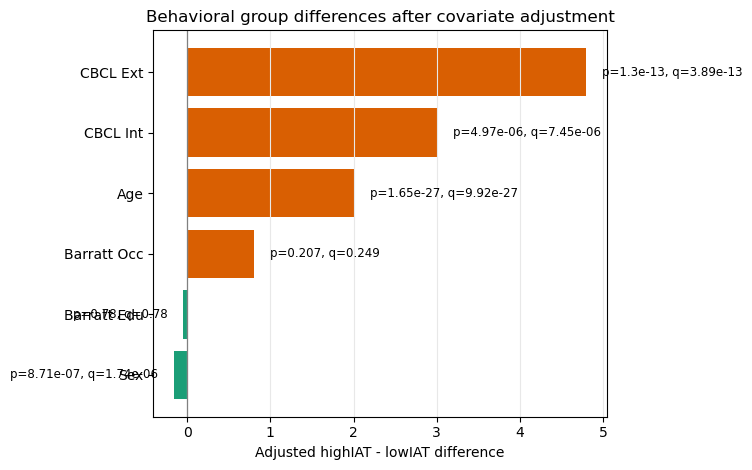

Saved: /Users/yiling/Desktop/YiZhang/CPM_comparingBehav/CPM_comparingBehav_adjusted_group_differences.png


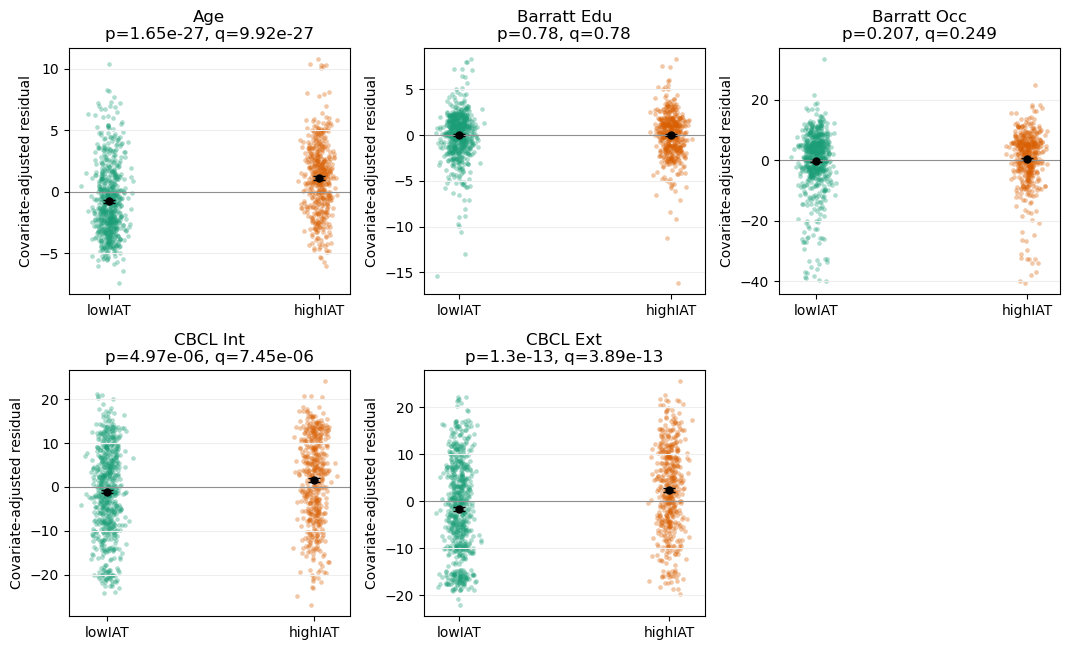

Saved: /Users/yiling/Desktop/YiZhang/CPM_comparingBehav/CPM_comparingBehav_adjusted_continuous_values.png


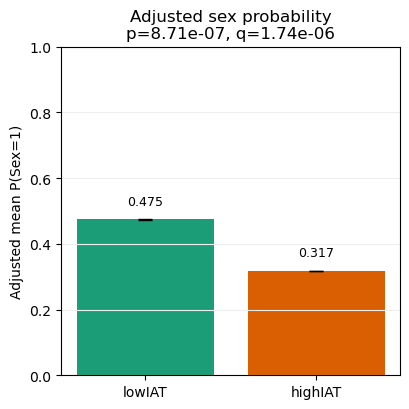

Saved: /Users/yiling/Desktop/YiZhang/CPM_comparingBehav/CPM_comparingBehav_adjusted_sex_probability.png


In [7]:
# ============================================================
# 7. 协变量校正后结果可视化
# ============================================================
adj_plot_df = adjusted_results_df.copy().sort_values('adjusted_difference_high_minus_low')

fig, ax = plt.subplots(figsize=(7.6, 4.8))
y_pos = np.arange(adj_plot_df.shape[0])
bar_colors = ['#d95f02' if v >= 0 else '#1b9e77' for v in adj_plot_df['adjusted_difference_high_minus_low']]
ax.barh(y_pos, adj_plot_df['adjusted_difference_high_minus_low'], color=bar_colors)
ax.axvline(0, color='#808080', linewidth=0.9)
ax.set_yticks(y_pos)
ax.set_yticklabels(adj_plot_df['target_label'])
ax.set_xlabel('Adjusted highIAT - lowIAT difference')
ax.set_title('Behavioral group differences after covariate adjustment')
ax.grid(True, axis='x', color='#e8e8e8', linewidth=0.8)

x_span = max(adj_plot_df['adjusted_difference_high_minus_low'].abs().max(), 1e-6)
x_pad = 0.04 * x_span
for row_idx, row in enumerate(adj_plot_df.itertuples(index=False)):
    x = row.adjusted_difference_high_minus_low
    x_text = x + x_pad if x >= 0 else x - x_pad
    ha = 'left' if x >= 0 else 'right'
    ax.text(
        x_text,
        row_idx,
        f'p={row.p_two_sided:.3g}, q={row.q_fdr:.3g}',
        va='center',
        ha=ha,
        fontsize=8.5,
    )

fig.tight_layout()
adj_bar_fig_path = RESULT_DIR / 'CPM_comparingBehav_adjusted_group_differences.png'
fig.savefig(adj_bar_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', adj_bar_fig_path)

# 7.2 连续变量的 covariate-only residual 分布。
continuous_targets = [target for target in TARGET_COLS if target not in BINARY_TARGETS]
fig, axes = plt.subplots(2, 3, figsize=(10.8, 6.6))
axes = axes.ravel()

rng = np.random.default_rng(2026)
group_order = ['lowIAT', 'highIAT']
group_colors = {'lowIAT': '#1b9e77', 'highIAT': '#d95f02'}

for ax, target in zip(axes, continuous_targets):
    sub_df = adjusted_values_df[adjusted_values_df['target'] == target]
    for x_idx, subgroup in enumerate(group_order):
        values = sub_df.loc[sub_df['subgroup'] == subgroup, 'covariate_adjusted_value'].to_numpy(dtype=float)
        jitter = rng.normal(0, 0.035, size=values.size)
        ax.scatter(
            np.full(values.size, x_idx) + jitter,
            values,
            s=11,
            alpha=0.35,
            color=group_colors[subgroup],
            linewidths=0,
        )
        mean = values.mean()
        sem = values.std(ddof=1) / np.sqrt(values.size)
        ax.errorbar(x_idx, mean, yerr=sem, fmt='o', color='black', capsize=4, markersize=5, linewidth=1.2)

    p_value = adjusted_results_df.loc[adjusted_results_df['target'] == target, 'p_two_sided'].iloc[0]
    q_value = adjusted_results_df.loc[adjusted_results_df['target'] == target, 'q_fdr'].iloc[0]
    ax.axhline(0, color='#909090', linewidth=0.8)
    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels(group_order)
    ax.set_title(f'{TARGET_LABELS[target]}\np={p_value:.3g}, q={q_value:.3g}')
    ax.set_ylabel('Covariate-adjusted residual')
    ax.grid(True, axis='y', color='#eeeeee', linewidth=0.8)

for ax in axes[len(continuous_targets):]:
    ax.axis('off')

fig.tight_layout()
adj_value_fig_path = RESULT_DIR / 'CPM_comparingBehav_adjusted_continuous_values.png'
fig.savefig(adj_value_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', adj_value_fig_path)

# 7.3 Sex 单独画调整后概率图。
sex_row = adjusted_results_df.loc[adjusted_results_df['target'].isin(BINARY_TARGETS)].iloc[0]
sex_means = [sex_row['adjusted_mean_lowIAT'], sex_row['adjusted_mean_highIAT']]
sex_ses = [sex_row['adjusted_se_lowIAT'], sex_row['adjusted_se_highIAT']]

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.bar(group_order, sex_means, yerr=sex_ses, capsize=5, color=[group_colors[g] for g in group_order])
ax.set_ylim(0, 1)
ax.set_ylabel('Adjusted mean P(Sex=1)')
ax.set_title(f'Adjusted sex probability\np={sex_row.p_two_sided:.3g}, q={sex_row.q_fdr:.3g}')
ax.grid(True, axis='y', color='#eeeeee', linewidth=0.8)

for x_idx, value in enumerate(sex_means):
    ax.text(x_idx, value + 0.035, f'{value:.3f}', ha='center', va='bottom', fontsize=9)

fig.tight_layout()
adj_sex_fig_path = RESULT_DIR / 'CPM_comparingBehav_adjusted_sex_probability.png'
fig.savefig(adj_sex_fig_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', adj_sex_fig_path)
